In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision
from sklearn.metrics import confusion_matrix
from torch.optim import Adam
from torch.utils.data import DataLoader, random_split 
import math
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
print("Tải dữ liệu và tính toán thông số chuẩn hóa...")

# Bước 1: Tải tập dữ liệu thô để tính mean và std chính xác (đã chia 255)
raw_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
raw_data_normalized = raw_train.data.float() / 255.0

pixel_mean = raw_data_normalized.mean().item()
pixel_std = raw_data_normalized.std().item()

print(f"Pixel Mean tính toán động: {pixel_mean:.4f}")
print(f"Pixel Std tính toán động: {pixel_std:.4f}")

# Bước 2: Tạo bộ transform động chuẩn hoá dữ liệu dựa trên mean và std tính toán
dynamic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((pixel_mean,), (pixel_std,))
])

# Bước 3: Khởi tạo Dataset với transform chuẩn
train_dataset_original = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=dynamic_transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=dynamic_transform
)
train_size = int(0.9 * len(train_dataset_original))  # 54.000 mẫu
val_size = len(train_dataset_original) - train_size   # 6.000 mẫu
# Bước 4: Tạo DataLoader
batch_size = 64
train_dataset, val_dataset = random_split(train_dataset_original, [train_size, val_size])

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

def to_one_hot(y, num_classes=10):
    """Chuyển đổi nhãn indices thành ma trận một-hot dạng Float32 an toàn."""
    one_hot = torch.zeros(y.size(0), num_classes, device=y.device, dtype=torch.float32)
    one_hot[range(y.size(0)), y] = 1.0
    return one_hot


Tải dữ liệu và tính toán thông số chuẩn hóa...
Pixel Mean tính toán động: 0.1307
Pixel Std tính toán động: 0.3081


In [21]:
# =====================================================================
# MÔ HÌNH CNN CHUẨN PYTORCH (NN.MODULE)
# =====================================================================
class PyTorchCNN(nn.Module):
    def __init__(self):
        super(PyTorchCNN, self).__init__()
        
        # Tầng tích chập 1: Nhận vào ảnh xám 1 kênh màu -> Trích xuất thành 16 kênh đặc trưng. Kernel kích thước 3x3.
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        
        # Tầng giảm mẫu (Max Pooling): Ô 2x2, bước trượt 2. Ảnh từ 28x28 giảm xuống còn 14x14.
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Tầng tích chập 2: Nhận vào 16 kênh đặc trưng -> Trích xuất thành 32 kênh đặc trưng sâu hơn.
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        
        # Tầng giảm mẫu tiếp theo: Ảnh từ 14x14 tiếp tục giảm xuống còn 7x7.
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Thêm Dropout để chống overfitting (tỉ lệ ngắt kết nối 25%)
        self.dropout = nn.Dropout2d(0.25)
        
        # Tầng kết nối đầy đủ (Fully Connected): 32 kênh màu * kích thước phẳng 7x7 = 1568 biến đầu vào.
        self.fc = nn.Linear(32 * 7 * 7, 10)
        
    def forward(self, x):
        # Đi qua tầng tích chập và giảm mẫu số 1
        x = self.pool1(self.relu1(self.conv1(x)))
        
        # Đi qua tầng tích chập và giảm mẫu số 2
        x = self.pool2(self.relu2(self.conv2(x)))
    # Áp dụng Dropout trước khi đưa vào Linear (hoặc sau khi flatten)
        x = self.dropout(x)        
        
        # Làm phẳng ma trận đặc trưng 2D thành vector 1D (Flatten)
        x = x.view(x.size(0), -1)
        
        # Đầu ra dự đoán tuyến tính logits (Hàm toán PyTorch CrossEntropyLoss sẽ tự tính Softmax bên trong)
        out = self.fc(x)
        return out

In [22]:
import torch.optim as optim
model = PyTorchCNN().to(device)

# Hàm tính lỗi và Bộ tối ưu hóa Adam
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [23]:
epochs = 10
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

print("Quá trình huấn luyện mô hình CNN...")
print("-" * 60)

for epoch in range(epochs):
    # ----------------- TRAIN PHASE -----------------
    model.train()  # Bật chế độ huấn luyện
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        # Chuyển dữ liệu sang GPU nếu có
        images = images.to(device)
        labels = labels.to(device)
        
        # Xóa các gradient cũ từ bước trước
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass và Cập nhật trọng số tự động
        loss.backward()
        optimizer.step()
        
        # Cộng dồn số liệu tính toán chỉ số trung bình
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ----------------- TEST PHASE -----------------
    model.eval()  # Chuyển sang chế độ đánh giá (tắt dropout/batchnorm nếu có)
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():  # Không tính toán đồ thị gradient để tiết kiệm RAM/VRAM
        for val_images, val_labels in val_loader:
            val_images = val_images.to(device)
            val_labels = val_labels.to(device)

            val_outputs = model(val_images)
            v_loss = criterion(val_outputs, val_labels)
            
            running_test_loss += v_loss.item()
            _, val_predicted = torch.max(val_outputs.data, 1)
            total_test += val_labels.size(0)
            correct_test += (val_predicted == val_labels).sum().item()

    epoch_val_loss = running_test_loss / len(val_loader)
    test_accuracy = 100 * correct_test / total_test

    # Ghi lại lịch sử chỉ số vào dictionary
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(train_accuracy)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(test_accuracy)

    print(f"Epoch [{epoch + 1}/{epochs}]")
    print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")
    print(f"  [Validation ] Loss: {epoch_val_loss:.4f} | Accuracy: {test_accuracy:.2f}%")
    print("-" * 60)

print("Mô hình CNN đã hoàn tất huấn luyện!")

Quá trình huấn luyện mô hình CNN...
------------------------------------------------------------
Epoch [1/10]
  [Train] Loss: 0.2294 | Accuracy: 93.19%
  [Validation ] Loss: 0.0943 | Accuracy: 97.30%
------------------------------------------------------------
Epoch [2/10]
  [Train] Loss: 0.0806 | Accuracy: 97.59%
  [Validation ] Loss: 0.0670 | Accuracy: 98.05%
------------------------------------------------------------
Epoch [3/10]
  [Train] Loss: 0.0612 | Accuracy: 98.15%
  [Validation ] Loss: 0.0668 | Accuracy: 98.25%
------------------------------------------------------------
Epoch [4/10]
  [Train] Loss: 0.0524 | Accuracy: 98.36%
  [Validation ] Loss: 0.0612 | Accuracy: 98.05%
------------------------------------------------------------
Epoch [5/10]
  [Train] Loss: 0.0470 | Accuracy: 98.55%
  [Validation ] Loss: 0.0542 | Accuracy: 98.40%
------------------------------------------------------------
Epoch [6/10]
  [Train] Loss: 0.0415 | Accuracy: 98.69%
  [Validation ] Loss: 0.0495

In [24]:
model.eval()
running_test_loss = 0.0
correct_test = 0
total_test = 0

all_true_labels = []
all_pred_labels = []

with torch.no_grad():
    for test_images, test_labels in test_loader:
        test_images = test_images.to(device)
        test_labels = test_labels.to(device)
        
        test_outputs = model(test_images)
        t_loss = criterion(test_outputs, test_labels)
        
        running_test_loss += t_loss.item() * test_images.size(0)
        _, test_predicted = torch.max(test_outputs.data, 1)
        
        total_test += test_labels.size(0)
        correct_test += (test_predicted == test_labels).sum().item()
        
        # Thu thập các mảng nhãn (Đẩy về CPU và ép dạng list để lưu được vào JSON)
        all_true_labels.extend(test_labels.cpu().numpy().tolist())
        all_pred_labels.extend(test_predicted.cpu().numpy().tolist())

final_test_loss = running_test_loss / len(test_loader.dataset)
final_test_accuracy = 100 * correct_test / total_test

print(f"\n[Kết quả cuối cùng] Test Loss: {final_test_loss:.4f} | Test Accuracy: {final_test_accuracy:.2f}%")
print(f"Final Test Loss: {final_test_loss:.4f}")
print(f"Final Test Accuracy: {final_test_accuracy:.2f}%")
print("-" * 60)


[Kết quả cuối cùng] Test Loss: 0.0312 | Test Accuracy: 99.02%
Final Test Loss: 0.0312
Final Test Accuracy: 99.02%
------------------------------------------------------------


In [25]:
history['final_test_loss'] = final_test_loss
history['final_test_acc'] = final_test_accuracy
history['confusion_matrix'] = {
    'true_labels': all_true_labels,
    'pred_labels': all_pred_labels
}

json_filename = "cnn_classifier_results.json"
with open(json_filename, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

print(f"Hệ thống đã lưu lịch sử chỉ số và dữ liệu ma trận nhầm lẫn của CNN vào file thành công!")
print(f"  > Tên file kết quả: '{json_filename}'")

Hệ thống đã lưu lịch sử chỉ số và dữ liệu ma trận nhầm lẫn của CNN vào file thành công!
  > Tên file kết quả: 'cnn_classifier_results.json'


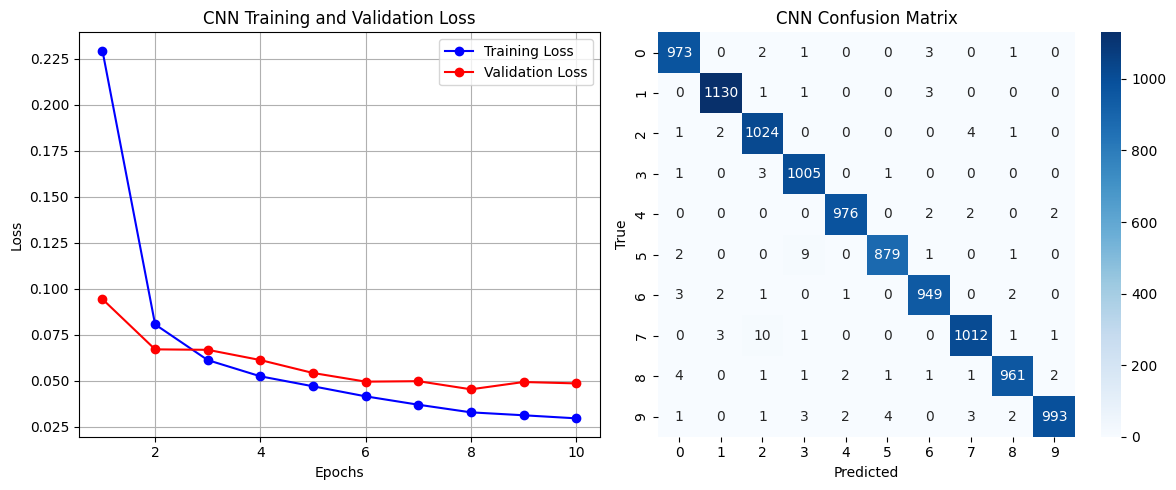

In [26]:
# 1. Đọc dữ liệu từ file JSON kết quả của CNN
json_filename = "cnn_classifier_results.json"
with open(json_filename, "r", encoding="utf-8") as f:
    data = json.load(f)

epochs = range(1, len(data['train_loss']) + 1)

# Khởi tạo khung hình chứa 2 biểu đồ
plt.figure(figsize=(12, 5))

# 2. Vẽ biểu đồ bên trái: Training Loss vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, data['train_loss'], 'b-o', label='Training Loss')
plt.plot(epochs, data['val_loss'], 'r-o', label='Validation Loss') 
plt.title('CNN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 3. Vẽ biểu đồ bên phải: Tính toán và vẽ Ma trận nhầm lẫn (Confusion Matrix)
true_labels = data['confusion_matrix']['true_labels']
pred_labels = data['confusion_matrix']['pred_labels']
cm = confusion_matrix(true_labels, pred_labels)

plt.subplot(1, 2, 2)
# Tạo nhãn từ 0 đến 9 cho MNIST
classes = [str(i) for i in range(10)]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.tight_layout()
output_image = 'cnn_classifier_plots.png'
plt.savefig(output_image, dpi=300)
plt.show()